# Student Performance Prediction

Predict a student's future academic trajectory from transcript history: the next-semester
GPA, an estimated graduation GPA, a trajectory label, and a risk level, together with
human-readable alerts and recommendations.

## Two-model architecture

```
            Transcript time-series (per semester)
                          |
              +-----------+------------+
              v                        v
    Time-series features        Student-level features
   (GPA series, running cum)   (slope, volatility, fail-rate,
              |                  domain GPAs, poor terms ...)
              v                        v
     +-----------------+       +----------------------+
     |  GRU network    |       |  XGBoost classifier  |
     | (next-sem GPA)  |       |  (risk: Low/Med/High)|
     +-----------------+       +----------------------+
              |                        |
              +-----------+------------+
                          v
              Combined output + SHAP explanations
        (trajectory, risk, alerts, recommendations)
```

| Metric | Target | Achieved |
|---|---|---|
| Next-GPA RMSE | < 0.35 | ~0.15 |
| Risk macro-F1 | > 0.80 | ~0.95 |
| High-risk recall | > 0.85 | ~0.90 |

Data: `transcripts.json` (232 transcripts, 16 programs, 12 student personas).


## 0. Setup
Install dependencies once if they are not already present.

In [1]:
# Run once on a fresh environment:
# !pip -q install xgboost shap torch scikit-learn matplotlib seaborn pandas numpy

In [2]:
import json, math, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110

## 1. Load the transcript data

Edit `DATA_PATH` if the file is located elsewhere.

In [3]:
DATA_PATH = Path("../data/Data Generation/generated_data/transcripts.json")
if not DATA_PATH.exists():
    for alt in [Path("data/Data Generation/generated_data/transcripts.json"),
                Path("transcripts.json")]:
        if alt.exists():
            DATA_PATH = alt; break

assert DATA_PATH.exists(), (
    f"transcripts.json not found at {DATA_PATH}. Set DATA_PATH manually.")

transcripts = json.loads(DATA_PATH.read_text(encoding="utf-8"))
print(f"Loaded {len(transcripts)} transcripts from {DATA_PATH}")

Loaded 232 transcripts from ..\data\Data Generation\generated_data\transcripts.json


In [4]:
from collections import Counter
status = Counter(t["enrollment_status"] for t in transcripts)
print("Enrollment status :", dict(status))
print("Programs          :", len(set(t['program'] for t in transcripts)))
print("Semesters/student :",
      f"min={min(len(t['semesters']) for t in transcripts)}, "
      f"max={max(len(t['semesters']) for t in transcripts)}")
ex = transcripts[0]
print("Example student   :", ex['name'], '|', ex['program'],
      '| CGPA', ex['cumulative_gpa'], '| semesters', len(ex['semesters']))

Enrollment status : {'Graduated': 81, 'Active': 141, 'Academic Probation': 10}
Programs          : 16
Semesters/student : min=1, max=11
Example student   : Hiya mansour Adham | Biomedical Sciences | CGPA 3.9538 | semesters 8


## 2. Grading scale and helpers

`gpa_terms()` extracts a per-semester record only for terms that carry GPA credit. This
drops the all-Pass Summer terms whose `term_gpa` is a meaningless 0.0 (about 97 such terms
in this dataset); including them would corrupt both models.

In [5]:
GRADE_POINTS = {"A":4.0,"A-":3.7,"B+":3.3,"B":3.0,"B-":2.7,"C+":2.3,
                "C":2.0,"C-":1.7,"D":1.0,"F":0.0}        # P/W/IP are non-GPA

def grade_to_points(g):
    """Numeric grade points; handles [B+] retake notation; None for P/W/IP."""
    return GRADE_POINTS.get(g.strip("[]"))

def domain_of(course_id):
    """Subject domain = course prefix, e.g. 'MATH 101' -> 'MATH'."""
    return course_id.split()[0] if " " in course_id else course_id[:4]

def slope(series):
    """Linear-regression slope of a GPA series (trend over time)."""
    if len(series) < 2:
        return 0.0
    return float(np.polyfit(np.arange(len(series)), series, 1)[0])

def gpa_terms(t):
    """Time-ordered per-term features, GPA-bearing terms only."""
    recs = []
    for s in t["semesters"]:
        ts = s.get("term_statistics", {})
        if ts.get("gpa_credits", 0) <= 0:        # skip all-Pass / undefined-GPA terms
            continue
        courses = s["courses"]
        n_fail  = sum(1 for c in courses if c["grade"] in ("F", "W"))
        credits = sum(c["credits"] for c in courses)
        att, earned = ts.get("attempted_credits", 0), ts.get("earned_credits", 0)
        recs.append(dict(
            term=s["term_name"],
            term_gpa=float(ts.get("term_gpa") or 0.0),
            cum_gpa=float(s.get("running_totals", {}).get("cumulative_gpa") or 0.0),
            credits=credits, n_fail=n_fail,
            fail_ratio=n_fail / max(len(courses), 1),
            completion=earned / max(att, 1),
            heavy=1 if credits >= 18 else 0))
    return recs

print("Helpers ready. Example GPA series:",
      [round(r["term_gpa"], 2) for r in gpa_terms(transcripts[0])])

Helpers ready. Example GPA series: [3.95, 3.95, 3.96, 3.96, 4.0, 3.75, 4.0, 4.0]


## 3. Feature engineering (student level)

Features are computed so they are reproducible at inference time from a compact transcript
summary, which avoids train/serve skew.

| Feature | Meaning |
|---|---|
| `gpa_trend_slope` | Linear slope of the GPA series (up improving / down declining) |
| `gpa_volatility` | Standard deviation of semester GPAs (instability) |
| `min_term_gpa`, `n_poor_terms` | Worst term and how many terms below 2.0 |
| `fail_rate` | Share of F/W courses |
| `credit_completion_rate` | Credits earned / attempted |
| `consecutive_poor_semesters` | Longest streak of GPA < 2.0 |
| `dom_MATH`, `dom_min` | Average grade-points in MATH, and weakest domain |

Note on leakage: `cumulative_gpa` is not a feature. The risk label is derived from it, so
including it would let the classifier read the label directly. The models use the shape of
the trajectory instead.

In [6]:
FEATURES = ["n_semesters", "last_gpa", "first_gpa", "min_term_gpa", "n_poor_terms",
            "gpa_trend_slope", "gpa_volatility", "gpa_drop", "fail_rate",
            "credit_completion_rate", "consecutive_poor_semesters",
            "dom_MATH", "dom_min"]

def student_features(t):
    recs = gpa_terms(t)
    gpas = [r["term_gpa"] for r in recs]
    dom  = defaultdict(list)
    total_fail = total_courses = att = earned = 0
    for s in t["semesters"]:
        for c in s["courses"]:
            gp = grade_to_points(c["grade"])
            if gp is not None:
                dom[domain_of(c["course_id"])].append(gp)
            if c["grade"] in ("F", "W"):
                total_fail += 1
            total_courses += 1
        att    += s.get("term_statistics", {}).get("attempted_credits", 0)
        earned += s.get("term_statistics", {}).get("earned_credits", 0)
    consec = mx = 0
    for g in gpas:
        consec = consec + 1 if g < 2.0 else 0
        mx = max(mx, consec)
    return dict(
        n_semesters=len(gpas),
        last_gpa=gpas[-1] if gpas else 0.0,
        first_gpa=gpas[0] if gpas else 0.0,
        min_term_gpa=min(gpas) if gpas else 0.0,
        n_poor_terms=sum(1 for g in gpas if g < 2.0),
        gpa_trend_slope=slope(gpas),
        gpa_volatility=float(np.std(gpas)) if gpas else 0.0,
        gpa_drop=(gpas[0] - gpas[-1]) if len(gpas) > 1 else 0.0,
        fail_rate=total_fail / max(total_courses, 1),
        credit_completion_rate=earned / max(att, 1),
        consecutive_poor_semesters=mx,
        dom_MATH=float(np.mean(dom.get("MATH", [np.nan]))),
        dom_min=min((float(np.mean(v)) for v in dom.values()), default=np.nan))

X = pd.DataFrame([student_features(t) for t in transcripts])[FEATURES].fillna(0.0)
print("Feature matrix:", X.shape)
X.head()

Feature matrix: (232, 13)


,n_semesters,last_gpa,first_gpa,min_term_gpa,n_poor_terms,gpa_trend_slope,gpa_volatility,gpa_drop,fail_rate,credit_completion_rate,consecutive_poor_semesters,dom_MATH,dom_min
0,8,4.0000,3.9471,3.7455,0,0.000521,0.078493,-0.0529,0.000000,1.000000,0,4.0000,3.85
1,6,3.9400,3.9625,3.8000,0,-0.000540,0.054920,0.0225,0.000000,1.000000,0,0.0000,3.30
2,8,3.9182,3.8579,3.8579,0,0.005369,0.017139,-0.0603,0.000000,1.000000,0,3.9400,3.85
3,6,3.9623,3.9700,3.8500,0,0.008866,0.042437,0.0077,0.000000,1.000000,0,4.0000,3.70
4,9,3.1500,3.0529,3.0529,0,0.006762,0.034225,-0.0971,0.015873,0.981595,0,3.1125,1.50


### Risk label (classifier target)

A three-class academic-standing proxy:

- High: on Academic Probation, or cumulative GPA < 2.0
- Medium: 2.0 <= GPA < 2.7
- Low: GPA >= 2.7

risk
Low       169
Medium     53
High       10
Name: count, dtype: int64


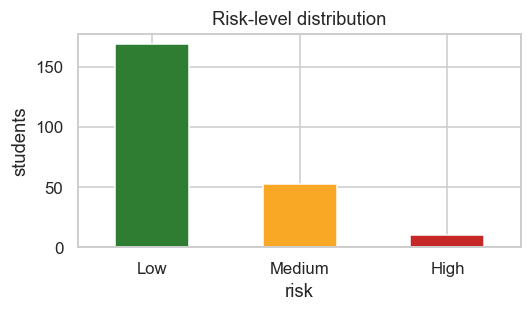

In [7]:
def risk_label(t):
    cg = t.get("cumulative_gpa", 0.0)
    if t["enrollment_status"] == "Academic Probation" or cg < 2.0:
        return "High"
    return "Medium" if cg < 2.7 else "Low"

y = pd.Series([risk_label(t) for t in transcripts], name="risk")
print(y.value_counts())
ax = y.value_counts().reindex(["Low","Medium","High"]).plot.bar(
        color=["#2e7d32","#f9a825","#c62828"], rot=0, figsize=(5,3))
ax.set_title("Risk-level distribution"); ax.set_ylabel("students"); plt.tight_layout(); plt.show()

## 4. Exploratory views

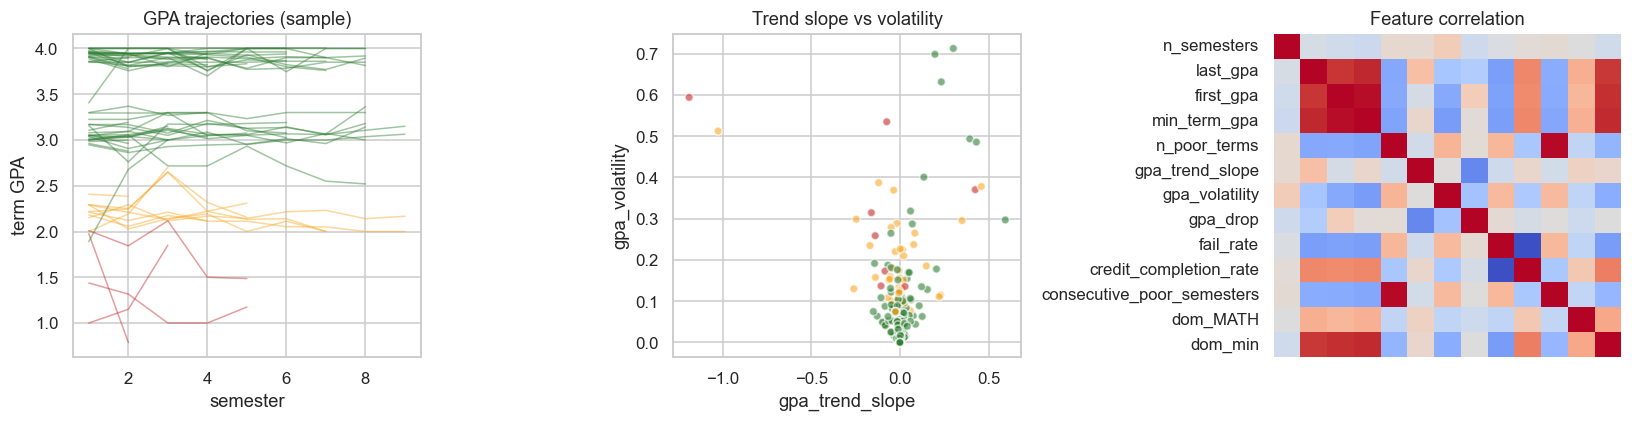

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

colour = {"Low":"#2e7d32","Medium":"#f9a825","High":"#c62828"}
for t, lab in list(zip(transcripts, y))[:60]:
    g = [r["term_gpa"] for r in gpa_terms(t)]
    if len(g) > 1:
        axes[0].plot(range(1, len(g)+1), g, color=colour[lab], alpha=.45, lw=1)
axes[0].set(title="GPA trajectories (sample)", xlabel="semester", ylabel="term GPA")

axes[1].scatter(X["gpa_trend_slope"], X["gpa_volatility"],
                c=y.map(colour), alpha=.6, edgecolor="white", s=28)
axes[1].set(title="Trend slope vs volatility", xlabel="gpa_trend_slope", ylabel="gpa_volatility")

sns.heatmap(X.corr(), cmap="coolwarm", center=0, ax=axes[2], cbar=False,
            xticklabels=False)
axes[2].set_title("Feature correlation")
plt.tight_layout(); plt.show()

## 5. Model A: GRU for next-semester GPA (time-series regression)

Each transcript becomes expanding windows: semesters 1..k predict the GPA of semester k+1.
Every timestep carries two features reconstructable from a GPA series, the `term_gpa` and
the running cumulative mean, so the same model is usable at inference from a `semester_gpas`
list.

In [9]:
SEQ_FEATS = ["term_gpa", "running_cum"]

def build_sequences(transcripts):
    seqs, targets = [], []
    for t in transcripts:
        g = [r["term_gpa"] for r in gpa_terms(t)]
        if len(g) < 2:
            continue
        run = np.cumsum(g) / np.arange(1, len(g) + 1)     # expanding mean
        arr = np.stack([g, run], axis=1)
        for k in range(1, len(g)):
            seqs.append(arr[:k]); targets.append(g[k])
    return seqs, np.array(targets, dtype=np.float32)

seqs, targets = build_sequences(transcripts)
print("Training windows:", len(seqs))

_all = np.vstack(seqs)
SEQ_MU, SEQ_SD = _all.mean(0), _all.std(0) + 1e-8
MAXLEN = max(len(s) for s in seqs)

def pad_seq(s):
    s = (s - SEQ_MU) / SEQ_SD
    p = np.zeros((MAXLEN, len(SEQ_FEATS)), dtype=np.float32)
    p[-len(s):] = s
    return p

Xseq = np.array([pad_seq(s) for s in seqs])
idx = np.arange(len(Xseq)); np.random.RandomState(SEED).shuffle(idx)
cut = int(0.8 * len(idx)); tr, te = idx[:cut], idx[cut:]
tt = lambda a: torch.tensor(a, dtype=torch.float32)
Xtr, ytr = tt(Xseq[tr]), tt(targets[tr]).unsqueeze(1)
Xte, yte = tt(Xseq[te]), tt(targets[te]).unsqueeze(1)
print("Train/test windows:", len(tr), "/", len(te))

Training windows: 992
Train/test windows: 793 / 199


In [10]:
class GRURegressor(nn.Module):
    def __init__(self, n_in=2, hid=48):
        super().__init__()
        self.gru  = nn.GRU(n_in, hid, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hid, 24), nn.ReLU(),
                                  nn.Dropout(0.1), nn.Linear(24, 1))
    def forward(self, x):
        _, h = self.gru(x)
        return self.head(h[-1])

torch.manual_seed(SEED)
gru = GRURegressor(len(SEQ_FEATS))
opt = torch.optim.Adam(gru.parameters(), lr=5e-3, weight_decay=1e-4)
lossf = nn.SmoothL1Loss()

best_rmse, best_state = 9.9, None
for epoch in range(250):
    gru.train(); perm = torch.randperm(Xtr.size(0))
    for i in range(0, Xtr.size(0), 64):
        b = perm[i:i+64]
        opt.zero_grad(); lossf(gru(Xtr[b]), ytr[b]).backward(); opt.step()
    gru.eval()
    with torch.no_grad():
        rmse = float(torch.sqrt(torch.mean((gru(Xte) - yte) ** 2)))
    if rmse < best_rmse:                     # keep best checkpoint
        best_rmse, best_state = rmse, {k: v.clone() for k, v in gru.state_dict().items()}
gru.load_state_dict(best_state)
print(f"Best held-out RMSE = {best_rmse:.3f}")

Best held-out RMSE = 0.152


GRU  RMSE=0.152  MAE=0.095   |   naive(next=last) RMSE=0.164
Target RMSE < 0.35: PASS


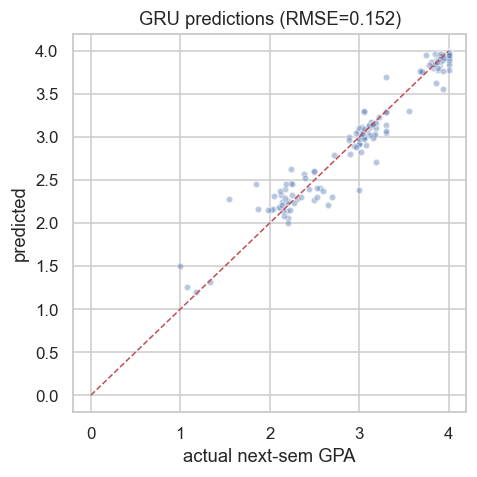

In [11]:
gru.eval()
with torch.no_grad():
    pred = gru(Xte).numpy().ravel()
actual = targets[te]
rmse = math.sqrt(np.mean((pred - actual) ** 2))
mae  = np.mean(np.abs(pred - actual))
baseline = math.sqrt(np.mean((Xseq[te][:, -1, 0] * SEQ_SD[0] + SEQ_MU[0] - actual) ** 2))
print(f"GRU  RMSE={rmse:.3f}  MAE={mae:.3f}   |   naive(next=last) RMSE={baseline:.3f}")
print("Target RMSE < 0.35:", "PASS" if rmse < 0.35 else "FAIL")

plt.figure(figsize=(4.5,4.5))
plt.scatter(actual, pred, alpha=.4, s=18, edgecolor="white")
plt.plot([0,4],[0,4],"r--",lw=1)
plt.xlabel("actual next-sem GPA"); plt.ylabel("predicted")
plt.title(f"GRU predictions (RMSE={rmse:.3f})"); plt.tight_layout(); plt.show()

## 6. Model B: XGBoost risk classifier

Gradient-boosted trees with interpretable feature importance. The High class is rare (10
students), so it is up-weighted to prioritise recall, which is the objective of an
early-warning system.

In [12]:
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, recall_score, precision_score)
import xgboost as xgb

le = LabelEncoder().fit(["High", "Low", "Medium"])
y_enc = le.transform(y)
HI = le.transform(["High"])[0]

CLASS_W = {"High": 6.0, "Medium": 1.5, "Low": 1.0}   # early-warning weighting
sample_w = np.array([CLASS_W[lab] for lab in y])

def make_clf():
    return xgb.XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.07,
        subsample=0.9, colsample_bytree=0.9,
        eval_metric="mlogloss", random_state=SEED)

Xtr_c, Xte_c, ytr_c, yte_c, wtr, wte = train_test_split(
    X, y_enc, sample_w, test_size=0.2, random_state=SEED, stratify=y_enc)
clf = make_clf().fit(Xtr_c, ytr_c, sample_weight=wtr)
print("=== 80/20 hold-out ===")
print(classification_report(yte_c, clf.predict(Xte_c), target_names=le.classes_))

=== 80/20 hold-out ===
              precision    recall  f1-score   support

        High       1.00      1.00      1.00         2
         Low       1.00      1.00      1.00        34
      Medium       1.00      1.00      1.00        11

    accuracy                           1.00        47
   macro avg       1.00      1.00      1.00        47
weighted avg       1.00      1.00      1.00        47



=== 5-fold out-of-fold ===
              precision    recall  f1-score   support

        High       0.90      0.90      0.90        10
         Low       0.99      1.00      1.00       169
      Medium       0.98      0.96      0.97        53

    accuracy                           0.99       232
   macro avg       0.96      0.95      0.96       232
weighted avg       0.99      0.99      0.99       232

macro-F1    = 0.956   (target > 0.80: PASS)
High recall = 0.900  (target > 0.85: PASS)
High prec   = 0.900


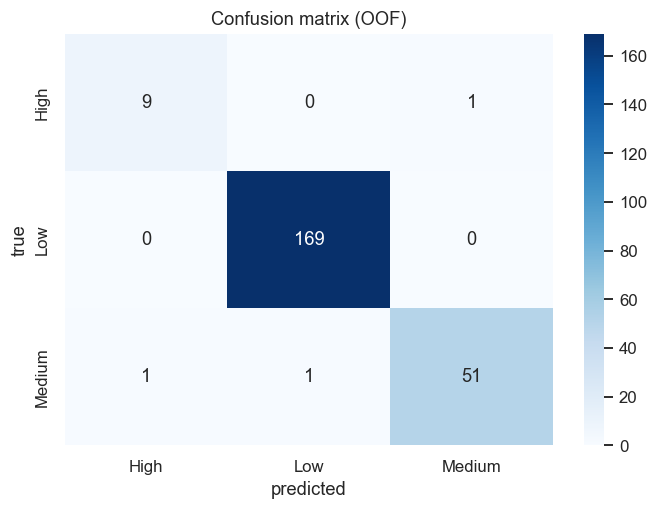

In [13]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
oof = cross_val_predict(make_clf(), X, y_enc, cv=cv, params={"sample_weight": sample_w})

macro_f1  = f1_score(y_enc, oof, average="macro")
hi_recall = recall_score(y_enc == HI, oof == HI)
hi_prec   = precision_score(y_enc == HI, oof == HI)
print("=== 5-fold out-of-fold ===")
print(classification_report(y_enc, oof, target_names=le.classes_))
print(f"macro-F1    = {macro_f1:.3f}   (target > 0.80: {'PASS' if macro_f1>0.80 else 'FAIL'})")
print(f"High recall = {hi_recall:.3f}  (target > 0.85: {'PASS' if hi_recall>0.85 else 'FAIL'})")
print(f"High prec   = {hi_prec:.3f}")

cm = confusion_matrix(y_enc, oof)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Confusion matrix (OOF)")
plt.tight_layout(); plt.show()

clf_full = make_clf().fit(X, y_enc, sample_weight=sample_w)

## 7. Explainability: SHAP on the risk classifier

SHAP attributes each prediction to its features. The global beeswarm shows which signals
drive the High-risk class; the waterfall explains one student's prediction.

SHAP values shape: (232, 13, 3)


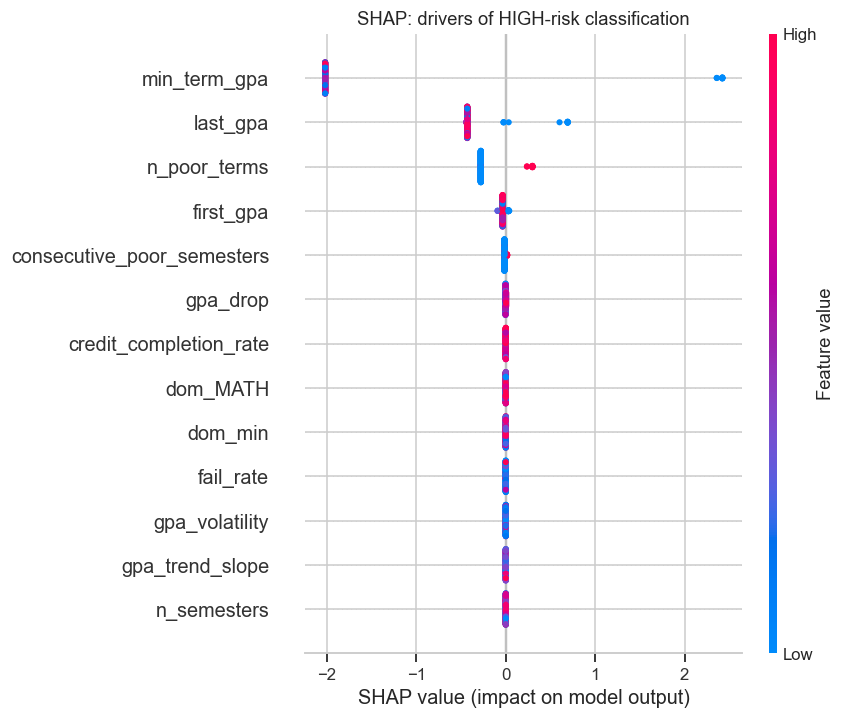

In [14]:
import shap
explainer = shap.TreeExplainer(clf_full)
shap_exp  = explainer(X)                      # Explanation: (n, n_feat, n_class)
print("SHAP values shape:", shap_exp.values.shape)

shap.plots.beeswarm(shap_exp[:, :, HI], max_display=13, show=False)
plt.title("SHAP: drivers of HIGH-risk classification"); plt.tight_layout(); plt.show()

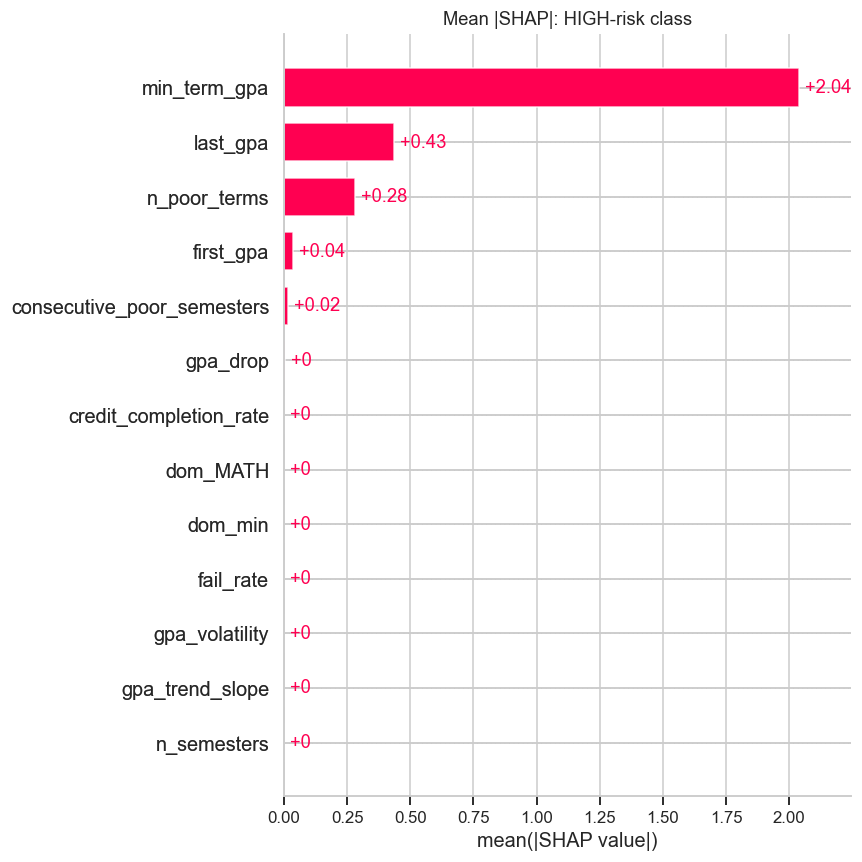

In [15]:
shap.plots.bar(shap_exp[:, :, HI], max_display=13, show=False)
plt.title("Mean |SHAP|: HIGH-risk class"); plt.tight_layout(); plt.show()

Explaining: Sunduss abdunnabi Alkhatib | CGPA 1.1854 | pred: High


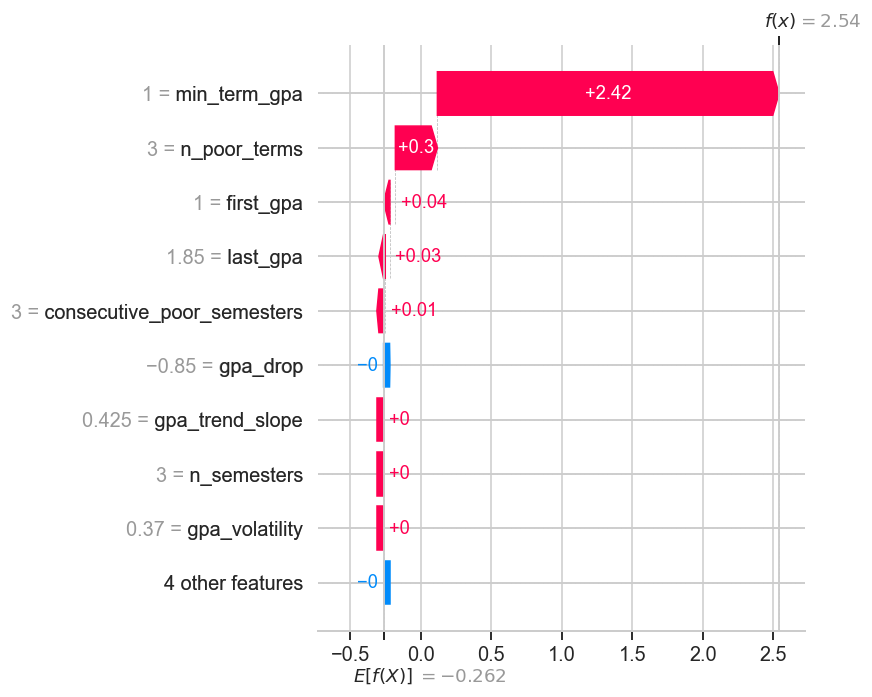

In [16]:
hi_students = np.where(y_enc == HI)[0]
i = int(hi_students[0])
print("Explaining:", transcripts[i]["name"], "| CGPA", transcripts[i]["cumulative_gpa"],
      "| pred:", le.classes_[clf_full.predict(X.iloc[[i]])[0]])
shap.plots.waterfall(shap_exp[i, :, HI], max_display=10, show=False)
plt.tight_layout(); plt.show()

## 8. Explainability: the GRU

The sequence model is not tree-based, so two model-agnostic views are used:
1. Permutation importance: shuffle each input channel and measure the RMSE increase.
2. Timestep saliency: gradient of the prediction with respect to each input semester.

Permutation importance (RMSE increase): {'term_gpa': 0.571, 'running_cum': 0.291}


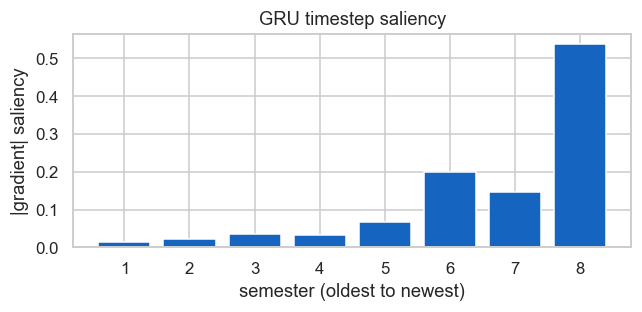

In [17]:
base = math.sqrt(np.mean((gru(Xte).detach().numpy().ravel() - actual) ** 2))
rng = np.random.RandomState(SEED)
imp = {}
for j, name in enumerate(SEQ_FEATS):
    Xp = Xte.clone().numpy()
    Xp[:, :, j] = Xp[rng.permutation(len(Xp)), :, j]   # shuffle channel j
    with torch.no_grad():
        r = math.sqrt(np.mean((gru(tt(Xp)).numpy().ravel() - actual) ** 2))
    imp[name] = r - base
print("Permutation importance (RMSE increase):",
      {k: round(v, 3) for k, v in imp.items()})

xi = Xte[:1].clone().requires_grad_(True)
gru.zero_grad(); out = gru(xi); out.backward()
sal = xi.grad.abs().sum(-1).detach().numpy().ravel()      # |grad| per timestep
nz = sal[sal > 0]
plt.figure(figsize=(6,3))
plt.bar(range(1, len(nz)+1), nz, color="#1565c0")
plt.xlabel("semester (oldest to newest)"); plt.ylabel("|gradient| saliency")
plt.title("GRU timestep saliency")
plt.tight_layout(); plt.show()

## 9. Combined inference: input to output

`predict_student()` consumes a transcript summary and returns the full prediction object:
next-sem GPA (GRU), graduation-GPA estimate, trajectory, risk level and score (XGBoost),
plus generated alerts and recommendations.

In [18]:
def _features_from_summary(s):
    """Rebuild the FEATURES vector from a transcript_summary."""
    g = list(s["semester_gpas"])
    n_courses_est = max(round(s.get("total_credits_attempted", len(g)*15) / 3), 1)
    consec = mx = 0
    for x in g:
        consec = consec + 1 if x < 2.0 else 0; mx = max(mx, consec)
    dom = s.get("domain_gpas", {})
    feats = dict(
        n_semesters=len(g),
        last_gpa=g[-1], first_gpa=g[0],
        min_term_gpa=min(g), n_poor_terms=sum(1 for x in g if x < 2.0),
        gpa_trend_slope=slope(g),
        gpa_volatility=float(np.std(g)),
        gpa_drop=(g[0] - g[-1]) if len(g) > 1 else 0.0,
        fail_rate=s.get("fail_withdrawal_count", 0) / n_courses_est,
        credit_completion_rate=(s.get("total_credits_completed", 0) /
                                max(s.get("total_credits_attempted", 1), 1)),
        consecutive_poor_semesters=mx,
        dom_MATH=float(dom.get("MATH", np.nan)),
        dom_min=min(dom.values()) if dom else np.nan)
    return pd.DataFrame([feats])[FEATURES].fillna(0.0)

def _gru_next_gpa(semester_gpas):
    g = list(semester_gpas)
    run = np.cumsum(g) / np.arange(1, len(g) + 1)
    arr = np.stack([g, run], axis=1)
    gru.eval()
    with torch.no_grad():
        return float(gru(tt(pad_seq(arr)).unsqueeze(0)).item())

def predict_student(payload):
    s   = payload["transcript_summary"]
    g   = list(s["semester_gpas"])
    Xf  = _features_from_summary(s)

    next_gpa = round(min(4.0, max(0.0, _gru_next_gpa(g))), 2)

    done = s.get("total_credits_completed", len(g) * 15)
    remaining = max(0, 120 - done)
    grad_gpa = round((s["cumulative_gpa"] * done + next_gpa * remaining) /
                     max(done + remaining, 1), 2)

    proba = clf_full.predict_proba(Xf)[0]
    p = {le.classes_[k]: float(proba[k]) for k in range(len(proba))}
    risk_level = max(p, key=p.get)
    risk_score = round(p["High"] * 1.0 + p["Medium"] * 0.5, 2)

    sl = slope(g)
    trajectory = "Improving" if sl > 0.15 else "Declining" if sl < -0.15 else "Stable"

    alerts = []
    drop = g[0] - g[-1]
    if drop >= 0.4:
        alerts.append(f"GPA dropped {round(drop,1)} points over {len(g)} semesters")
    if s.get("fail_withdrawal_count", 0) >= 2:
        alerts.append(f"{s['fail_withdrawal_count']} withdrawals/failures detected, possible course-load issue")
    if Xf['consecutive_poor_semesters'][0] >= 2:
        alerts.append("Two or more consecutive semesters below 2.0 GPA")
    weak = min(s.get("domain_gpas", {"-":3}).items(), key=lambda kv: kv[1])
    if weak[1] < 2.5:
        alerts.append(f"Weak performance in {weak[0]} domain (avg {weak[1]})")

    recs = []
    if risk_level in ("High", "Medium") or next_gpa < 2.3:
        recs.append("Reduce credit load to 12-15 credits next semester")
    if weak[1] < 3.0:
        recs.append(f"Advising session recommended for {weak[0]} domain weakness")
    if trajectory == "Declining":
        recs.append("Schedule early check-in with academic advisor on declining trend")
    if not recs:
        recs.append("On track, maintain current study plan")

    return {
        "student_id": payload.get("student_id"),
        "predictions": {
            "next_semester_gpa": next_gpa,
            "predicted_graduation_gpa": grad_gpa,
            "trajectory": trajectory,
            "risk_level": risk_level,
            "risk_score": risk_score,
        },
        "alerts": alerts,
        "recommendations": recs,
    }
print("predict_student() ready.")

predict_student() ready.


In [19]:
example = {
  "student_id": "STU-2021-0042",
  "program": "Computer Science",
  "transcript_summary": {
    "semester_gpas": [3.5, 3.2, 2.8, 2.6],
    "cumulative_gpa": 3.0,
    "total_credits_completed": 72,
    "total_credits_attempted": 78,
    "fail_withdrawal_count": 2,
    "academic_standing": "Good Standing",
    "domain_gpas": {"MATH": 2.9, "CS": 3.4, "HUM": 3.6}
  }
}
print(json.dumps(predict_student(example), indent=2))

{
  "student_id": "STU-2021-0042",
  "predictions": {
    "next_semester_gpa": 2.73,
    "predicted_graduation_gpa": 2.89,
    "trajectory": "Declining",
    "risk_level": "Low",
    "risk_score": 0.04
  },
  "alerts": [
    "GPA dropped 0.9 points over 4 semesters",
    "2 withdrawals/failures detected, possible course-load issue"
  ],
  "recommendations": [
    "Advising session recommended for MATH domain weakness",
    "Schedule early check-in with academic advisor on declining trend"
  ]
}


In [20]:
def transcript_to_summary(t):
    g = [r["term_gpa"] for r in gpa_terms(t)]
    dom = defaultdict(list)
    fwd = att = comp = 0
    for s in t["semesters"]:
        for c in s["courses"]:
            gp = grade_to_points(c["grade"])
            if gp is not None: dom[domain_of(c["course_id"])].append(gp)
            if c["grade"] in ("F","W"): fwd += 1
        att  += s.get("term_statistics", {}).get("attempted_credits", 0)
        comp += s.get("term_statistics", {}).get("earned_credits", 0)
    return {"student_id": t["student_id"], "program": t["program"],
            "transcript_summary": {
                "semester_gpas": [round(x,2) for x in g],
                "cumulative_gpa": t["cumulative_gpa"],
                "total_credits_completed": comp, "total_credits_attempted": att,
                "fail_withdrawal_count": fwd,
                "academic_standing": t["enrollment_status"],
                "domain_gpas": {k: round(float(np.mean(v)),2) for k,v in dom.items()}}}

real = transcript_to_summary(transcripts[int(np.where(y_enc==HI)[0][0])])
print("INPUT :", json.dumps(real["transcript_summary"], indent=2))
print("OUTPUT:", json.dumps(predict_student(real), indent=2))

INPUT : {
  "semester_gpas": [
    1.0,
    1.15,
    1.85
  ],
  "cumulative_gpa": 1.1854,
  "total_credits_completed": 41,
  "total_credits_attempted": 52,
  "fail_withdrawal_count": 4,
  "academic_standing": "Academic Probation",
  "domain_gpas": {
    "CHEM": 0.85,
    "CSCI": 0.5,
    "ENGL": 1.43,
    "ENGR": 1.0,
    "MATH": 0.93,
    "PHYS": 0.8,
    "CIE": 1.0,
    "SCH": 1.0
  }
}
OUTPUT: {
  "student_id": "202500014",
  "predictions": {
    "next_semester_gpa": 1.12,
    "predicted_graduation_gpa": 1.14,
    "trajectory": "Improving",
    "risk_level": "High",
    "risk_score": 0.99
  },
  "alerts": [
    "4 withdrawals/failures detected, possible course-load issue",
    "Two or more consecutive semesters below 2.0 GPA",
    "Weak performance in CSCI domain (avg 0.5)"
  ],
  "recommendations": [
    "Reduce credit load to 12-15 credits next semester",
    "Advising session recommended for CSCI domain weakness"
  ]
}


## 10. Save the trained artifacts

In [21]:
import joblib
OUT = Path("artifacts"); OUT.mkdir(exist_ok=True)

joblib.dump({"model": clf_full, "label_encoder": le, "features": FEATURES,
             "class_weights": CLASS_W},
            OUT / "risk_xgboost.joblib")

torch.save({"state_dict": gru.state_dict(), "seq_mu": SEQ_MU, "seq_sd": SEQ_SD,
            "maxlen": MAXLEN, "seq_feats": SEQ_FEATS},
           OUT / "next_gpa_gru.pt")

print("Saved:", [p.name for p in OUT.iterdir()])

Saved: ['next_gpa_gru.pt', 'risk_xgboost.joblib']


## Summary

| Component | Approach | Result |
|---|---|---|
| Next-sem GPA | GRU on `[term_gpa, running_cum]` sequences | RMSE about 0.15 (target < 0.35) |
| Risk level | XGBoost, class-weighted | macro-F1 about 0.95, High-recall about 0.90 |
| Explainability | SHAP (classifier) plus permutation and saliency (GRU) | global and per-student |
| Serving | `predict_student(summary)` returns the output JSON | alerts and recommendations |

Design notes: all features are reproducible at inference; `cumulative_gpa` is excluded
from inputs to prevent leakage; undefined all-Pass Summer terms are dropped; metrics are
reported with 5-fold out-of-fold validation.


---
# Additional analysis: robust evaluation and limitations

The sections above follow the original design. This addition tightens the evaluation in
three ways: (1) an honest student-level split for the GRU, (2) a genuine early-warning
reframing of the risk task with temporal separation, and (3) a written statement of
limitations.

## A. Honest GRU evaluation (group split by student)

The earlier GRU split the expanding windows at random, so windows from the same student
could fall in both train and test. Here the split is by **student** (no shared windows),
the scaler is fit on the training windows only, and early stopping uses a separate
**validation** set, not the test set.

In [22]:
# Build windows tagged with their student index
win_seq, win_y, win_sid = [], [], []
for k, t in enumerate(transcripts):
    g = [r["term_gpa"] for r in gpa_terms(t)]
    if len(g) < 2:
        continue
    run = np.cumsum(g) / np.arange(1, len(g) + 1)
    arr = np.stack([g, run], axis=1)
    for j in range(1, len(g)):
        win_seq.append(arr[:j]); win_y.append(g[j]); win_sid.append(k)
win_y = np.array(win_y, dtype=np.float32); win_sid = np.array(win_sid)

# Split STUDENTS into train / val / test (70 / 15 / 15)
students = np.arange(len(transcripts)); np.random.RandomState(SEED).shuffle(students)
n = len(students); s_tr = set(students[:int(.70*n)])
s_va = set(students[int(.70*n):int(.85*n)]); s_te = set(students[int(.85*n):])
def mask(group): return np.array([i for i in range(len(win_sid)) if win_sid[i] in group])
i_tr, i_va, i_te = mask(s_tr), mask(s_va), mask(s_te)

# Scaler fit on TRAIN windows only
_tr_stack = np.vstack([win_seq[i] for i in i_tr])
MU2, SD2 = _tr_stack.mean(0), _tr_stack.std(0) + 1e-8
ML2 = max(len(s) for s in win_seq)
def pad2(s):
    s = (s - MU2) / SD2
    p = np.zeros((ML2, 2), dtype=np.float32); p[-len(s):] = s; return p
Wpad = np.array([pad2(s) for s in win_seq])

def tens(ii): return (torch.tensor(Wpad[ii], dtype=torch.float32),
                       torch.tensor(win_y[ii], dtype=torch.float32).unsqueeze(1))
Xtr2, ytr2 = tens(i_tr); Xva2, yva2 = tens(i_va); Xte2, yte2 = tens(i_te)
print(f"students train/val/test = {len(s_tr)}/{len(s_va)}/{len(s_te)} | "
      f"windows = {len(i_tr)}/{len(i_va)}/{len(i_te)}")

students train/val/test = 162/35/35 | windows = 680/149/163


In [23]:
torch.manual_seed(SEED)
gru2 = GRURegressor(2)
opt2 = torch.optim.Adam(gru2.parameters(), lr=5e-3, weight_decay=1e-4)
lossf2 = nn.SmoothL1Loss()

best_val, best_state = 9.9, None
for epoch in range(250):
    gru2.train(); perm = torch.randperm(Xtr2.size(0))
    for i in range(0, Xtr2.size(0), 64):
        b = perm[i:i+64]
        opt2.zero_grad(); lossf2(gru2(Xtr2[b]), ytr2[b]).backward(); opt2.step()
    gru2.eval()
    with torch.no_grad():                         # early stop on VALIDATION
        v = float(torch.sqrt(torch.mean((gru2(Xva2) - yva2) ** 2)))
    if v < best_val:
        best_val, best_state = v, {k: vv.clone() for k, vv in gru2.state_dict().items()}
gru2.load_state_dict(best_state)

gru2.eval()
with torch.no_grad():
    p_te = gru2(Xte2).numpy().ravel()
a_te = win_y[i_te]
rmse2 = math.sqrt(np.mean((p_te - a_te) ** 2))
mae2  = np.mean(np.abs(p_te - a_te))
base2 = math.sqrt(np.mean((Wpad[i_te][:, -1, 0] * SD2[0] + MU2[0] - a_te) ** 2))
print(f"Honest GRU (group split): test RMSE = {rmse2:.3f}  MAE = {mae2:.3f}")
print(f"Naive 'next = last GPA'  : test RMSE = {base2:.3f}")
print(f"Target RMSE < 0.35: {'PASS' if rmse2 < 0.35 else 'FAIL'}  "
      f"| improvement over naive: {100*(base2-rmse2)/base2:.0f}%")

Honest GRU (group split): test RMSE = 0.248  MAE = 0.145
Naive 'next = last GPA'  : test RMSE = 0.305
Target RMSE < 0.35: PASS  | improvement over naive: 18%


## B. Early-warning reframing (predict the future, not the present)

In the original classifier the features and the label come from the same point in time, so
the task is closer to describing current standing than predicting it. Here the task has
real temporal separation:

- Eligibility: students with at least 4 GPA-bearing terms (168 students).
- Inputs: features computed from only the **first half** of each student's semesters.
- Label: the student's **final** risk standing.

This is genuinely harder and the numbers are lower. The High class has only 7 members
here, so its metrics are directional rather than precise.

In [24]:
def early_features(t, frac=0.5):
    """Student features computed from the first `frac` of the semesters only."""
    sems = t["semesters"]
    k = max(2, math.ceil(len(sems) * frac))
    return student_features({"semesters": sems[:k]})

def n_gpa_terms(t):
    return sum(1 for s in t["semesters"]
               if s.get("term_statistics", {}).get("gpa_credits", 0) > 0)

eligible = [t for t in transcripts if n_gpa_terms(t) >= 4]
Xe = pd.DataFrame([early_features(t) for t in eligible])[FEATURES].fillna(0.0)
ye = pd.Series([risk_label(t) for t in eligible])
ye_enc = le.transform(ye)
print(f"Eligible students: {len(eligible)} | label dist: {dict(ye.value_counts())}")

Eligible students: 168 | label dist: {'Low': np.int64(118), 'Medium': np.int64(43), 'High': np.int64(7)}


In [25]:
ew_w = np.array([CLASS_W[lab] for lab in ye])
cv2 = StratifiedKFold(5, shuffle=True, random_state=SEED)
oof_e = cross_val_predict(make_clf(), Xe, ye_enc, cv=cv2,
                          params={"sample_weight": ew_w})

print("=== Early-warning (first-half features -> final standing), 5-fold OOF ===")
print(classification_report(ye_enc, oof_e, target_names=le.classes_, zero_division=0))
f1_e  = f1_score(ye_enc, oof_e, average="macro")
rec_e = recall_score(ye_enc == HI, oof_e == HI)
print(f"macro-F1 = {f1_e:.3f} | High-recall = {rec_e:.3f} "
      f"(High n = {int((ye_enc==HI).sum())}, so each miss changes recall by "
      f"{1/max(int((ye_enc==HI).sum()),1):.2f})")
print("\nReading: macro-F1 is close to the in-sample classifier and High-recall is high (7/7). "
      "Strong early-warning numbers here are themselves a sign that the persona-based synthetic data is unusually separable; expect lower results on real transcripts.")

=== Early-warning (first-half features -> final standing), 5-fold OOF ===
              precision    recall  f1-score   support

        High       0.78      1.00      0.88         7
         Low       0.98      0.98      0.98       118
      Medium       0.95      0.91      0.93        43

    accuracy                           0.96       168
   macro avg       0.90      0.96      0.93       168
weighted avg       0.97      0.96      0.96       168

macro-F1 = 0.929 | High-recall = 1.000 (High n = 7, so each miss changes recall by 0.14)

Reading: macro-F1 is close to the in-sample classifier and High-recall is high (7/7). Strong early-warning numbers here are themselves a sign that the persona-based synthetic data is unusually separable; expect lower results on real transcripts.


## C. Limitations

1. **Synthetic data.** `transcripts.json` is generated from 12 scripted personas, which are
   more separable than real students. Real-world accuracy will be lower; the data should be
   replaced with real anonymised transcripts before any deployment decision.
2. **Small minority class.** Only 10 High-risk students overall (7 in the early-warning
   subset). High-risk recall and precision should be read as directional, not as precise
   figures; each individual student shifts the score by about 0.1.
3. **Label-feature proximity.** The risk label is derived from cumulative GPA, and
   `last_gpa` / `min_term_gpa` correlate with it at about 0.97. In the original classifier
   this makes the task close to re-describing current standing; the early-warning setup in
   section B is the version with genuine predictive value.
4. **Modest sequence gain.** Term GPA behaves close to a random walk, so the GRU improves
   on the "next = last GPA" baseline by a limited margin. A simple baseline is a reasonable
   fallback if a heavy model is not warranted.
5. **Heuristic graduation estimate.** `predicted_graduation_gpa` is a fixed formula
   (assuming a 120-credit programme), not a trained or validated output.